In [1]:
#impor packages
import pandas as pd
import numpy as np
from scipy import stats
from scipy.stats import zscore
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_T=pd.read_csv("../data/togo-dapaong_qc.csv")
df_T[:2]

,Timestamp,GHI,DNI,DHI,ModA,ModB,Tamb,RH,WS,WSgust,WSstdev,WD,WDstdev,BP,Cleaning,Precipitation,TModA,TModB,Comments
0,2021-10-25 00:01,-1.3,0.0,0.0,0.0,0.0,24.8,94.5,0.9,1.1,0.4,227.6,1.1,977,0,0.0,24.7,24.4,NaN
1,2021-10-25 00:02,-1.3,0.0,0.0,0.0,0.0,24.8,94.4,1.1,1.6,0.4,229.3,0.7,977,0,0.0,24.7,24.4,NaN


In [3]:
# Convert Timestamp to datetime
df_T['Timestamp'] = pd.to_datetime(df_T['Timestamp'], errors='coerce')
df_T.set_index('Timestamp', inplace=True)

In [4]:
df_T.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 525600 entries, 2021-10-25 00:01:00 to 2022-10-25 00:00:00
Data columns (total 18 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   GHI            525600 non-null  float64
 1   DNI            525600 non-null  float64
 2   DHI            525600 non-null  float64
 3   ModA           525600 non-null  float64
 4   ModB           525600 non-null  float64
 5   Tamb           525600 non-null  float64
 6   RH             525600 non-null  float64
 7   WS             525600 non-null  float64
 8   WSgust         525600 non-null  float64
 9   WSstdev        525600 non-null  float64
 10  WD             525600 non-null  float64
 11  WDstdev        525600 non-null  float64
 12  BP             525600 non-null  int64  
 13  Cleaning       525600 non-null  int64  
 14  Precipitation  525600 non-null  float64
 15  TModA          525600 non-null  float64
 16  TModB          525600 non-null  float64


In [5]:
df_T.describe()

,GHI,DNI,DHI,ModA,ModB,Tamb,RH,WS,WSgust,WSstdev,WD,WDstdev,BP,Cleaning,Precipitation,TModA,TModB,Comments
count,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,0.0
mean,230.555040,151.258469,116.444352,226.144375,219.568588,27.751788,55.013160,2.368093,3.229490,0.557740,161.741845,10.559568,975.915242,0.000535,0.001382,32.444403,33.543330,NaN
std,322.532347,250.956962,156.520714,317.346938,307.932510,4.758023,28.778732,1.462668,1.882565,0.268923,91.877217,5.915490,2.153977,0.023116,0.026350,10.998334,12.769277,NaN
min,-12.700000,0.000000,0.000000,0.000000,0.000000,14.900000,3.300000,0.000000,0.000000,0.000000,0.000000,0.000000,968.000000,0.000000,0.000000,13.100000,13.100000,NaN
25%,-2.200000,0.000000,0.000000,0.000000,0.000000,24.200000,26.500000,1.400000,1.900000,0.400000,74.800000,6.900000,975.000000,0.000000,0.000000,23.900000,23.600000,NaN
50%,2.100000,0.000000,2.500000,4.400000,4.300000,27.200000,59.300000,2.200000,2.900000,0.500000,199.100000,10.800000,976.000000,0.000000,0.000000,28.400000,28.400000,NaN
75%,442.400000,246.400000,215.700000,422.525000,411.000000,31.100000,80.800000,3.200000,4.400000,0.700000,233.500000,14.100000,977.000000,0.000000,0.000000,40.600000,43.000000,NaN
max,1424.000000,1004.500000,805.700000,1380.000000,1367.000000,41.400000,99.800000,16.100000,23.100000,4.700000,360.000000,86.900000,983.000000,1.000000,2.300000,70.400000,94.600000,NaN


In [6]:
df_T.isnull().sum()

GHI                   0
DNI                   0
DHI                   0
ModA                  0
ModB                  0
Tamb                  0
RH                    0
WS                    0
WSgust                0
WSstdev               0
WD                    0
WDstdev               0
BP                    0
Cleaning              0
Precipitation         0
TModA                 0
TModB                 0
Comments         525600
dtype: int64

In [7]:
df_T.drop_duplicates()

,GHI,DNI,DHI,ModA,ModB,Tamb,RH,WS,WSgust,WSstdev,WD,WDstdev,BP,Cleaning,Precipitation,TModA,TModB,Comments
Timestamp,,,,,,,,,,,,,,,,,,
2021-10-25 00:01:00,-1.3,0.0,0.0,0.0,0.0,24.8,94.5,0.9,1.1,0.4,227.6,1.1,977,0,0.0,24.7,24.4,NaN
2021-10-25 00:02:00,-1.3,0.0,0.0,0.0,0.0,24.8,94.4,1.1,1.6,0.4,229.3,0.7,977,0,0.0,24.7,24.4,NaN
2021-10-25 00:03:00,-1.3,0.0,0.0,0.0,0.0,24.8,94.4,1.2,1.4,0.3,228.5,2.9,977,0,0.0,24.7,24.4,NaN
2021-10-25 00:04:00,-1.2,0.0,0.0,0.0,0.0,24.8,94.3,1.2,1.6,0.3,229.1,4.6,977,0,0.0,24.7,24.4,NaN
2021-10-25 00:05:00,-1.2,0.0,0.0,0.0,0.0,24.8,94.0,1.3,1.6,0.4,227.5,1.6,977,0,0.0,24.7,24.4,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-10-24 23:56:00,-0.8,0.0,0.0,0.0,0.0,25.2,53.8,0.0,0.0,0.0,0.0,0.0,977,0,0.0,24.3,24.0,NaN
2022-10-24 23:57:00,-0.9,0.0,0.0,0.0,0.0,25.3,53.5,0.0,0.0,0.0,0.0,0.0,977,0,0.0,24.3,24.0,NaN
2022-10-24 23:58:00,-1.0,0.0,0.0,0.0,0.0,25.3,53.4,0.0,0.0,0.0,0.0,0.0,977,0,0.0,24.2,23.9,NaN


In [8]:
# Missing value report
missing_values = df_T.isna().sum()
print(missing_values[missing_values > 0])

Comments    525600
dtype: int64


In [9]:
# List columns with >5% nulls
threshold = 0.05 * len(df_T)
high_nulls = missing_values[missing_values > threshold]
print("Columns with >5% nulls:", high_nulls.index.tolist())

Columns with >5% nulls: ['Comments']


Outlier Detection & Basic Cleaning

In [10]:
# 2. Outlier Detection & Basic Cleaning
key_cols = ['GHI', 'DNI', 'DHI', 'ModA', 'ModB', 'WS', 'WSgust']
df_z = df_T[key_cols].apply(zscore)
df_T['outlier_flag'] = (np.abs(df_z) > 3).any(axis=1)
print(f"\nNumber of flagged outlier rows: {df_T['outlier_flag'].sum()}")


Number of flagged outlier rows: 9251


In [11]:
# Impute missing values in key columns with median
for col in key_cols + ['Tamb', 'RH', 'WD', 'BP', 'Cleaning', 'Precipitation', 'TModA', 'TModB']:
    if col in df_T.columns:
        df_T[col].fillna(df_T[col].median(), inplace=True)

In [12]:
country = 'Togo'
# Export cleaned DataFrame (outliers flagged, missings imputed)
clean_path = f'data/{country}_clean.csv'
df_T.to_csv(clean_path, index=True)  # Keep index as Timestamp
print(f"\nCleaned data exported to {clean_path}")


Cleaned data exported to data/Togo_clean.csv


<Figure size 1200x600 with 0 Axes>

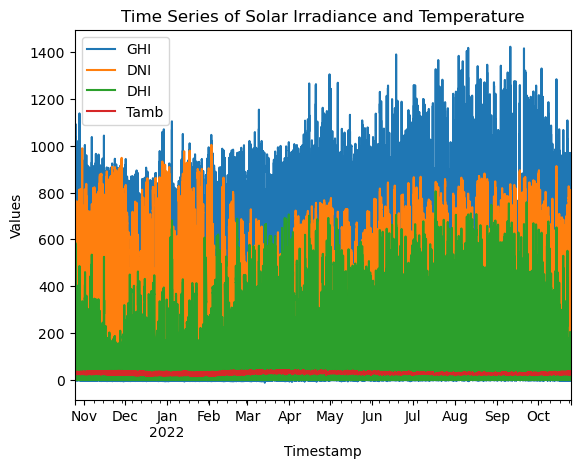

In [13]:
# 3. Time Series Analysis
# Line charts of GHI, DNI, DHI, Tamb vs. Timestamp
plt.figure(figsize=(12, 6))
df_T[['GHI', 'DNI', 'DHI', 'Tamb']].plot()
plt.title('Time Series of Solar Irradiance and Temperature')
plt.xlabel('Timestamp')
plt.ylabel('Values')
plt.show()

<Figure size 1200x600 with 0 Axes>

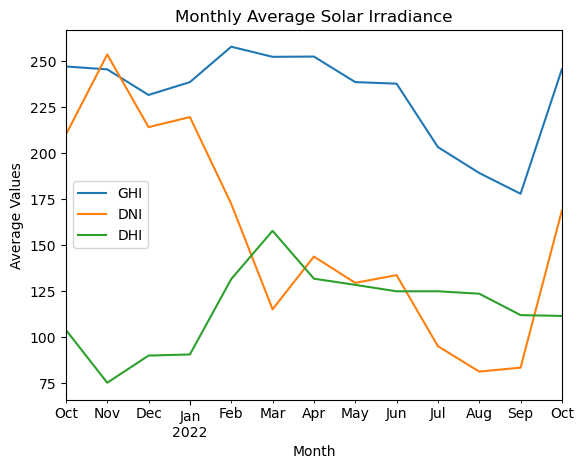

In [14]:
# Monthly patterns
monthly = df_T.resample('M').mean()
plt.figure(figsize=(12, 6))
monthly[['GHI', 'DNI', 'DHI']].plot()
plt.title('Monthly Average Solar Irradiance')
plt.xlabel('Month')
plt.ylabel('Average Values')
plt.show()

<Figure size 1200x600 with 0 Axes>

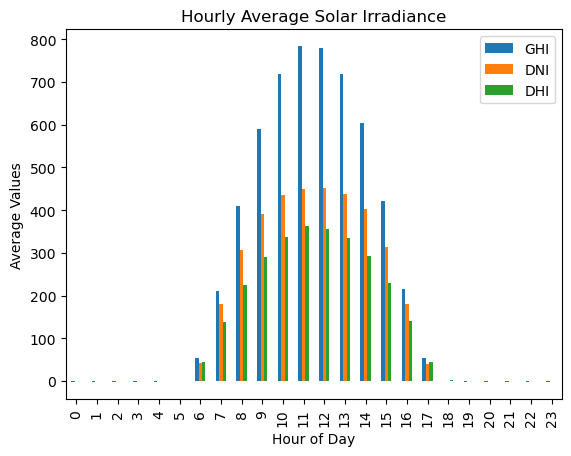

In [15]:
# Daily trends (by hour)
df_T['hour'] = df_T.index.hour
hourly = df_T.groupby('hour').mean()
plt.figure(figsize=(12, 6))
hourly[['GHI', 'DNI', 'DHI']].plot(kind='bar')
plt.title('Hourly Average Solar Irradiance')
plt.xlabel('Hour of Day')
plt.ylabel('Average Values')
plt.show()

<Figure size 800x500 with 0 Axes>

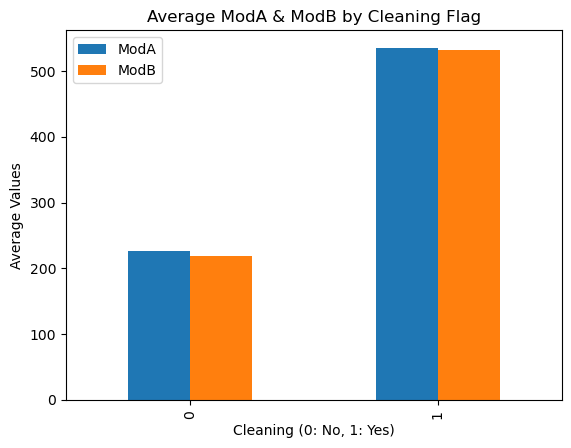

In [16]:
# 4. Cleaning Impact
clean_group = df_T.groupby('Cleaning')[['ModA', 'ModB']].mean()
plt.figure(figsize=(8, 5))
clean_group.plot(kind='bar')
plt.title('Average ModA & ModB by Cleaning Flag')
plt.xlabel('Cleaning (0: No, 1: Yes)')
plt.ylabel('Average Values')
plt.show()

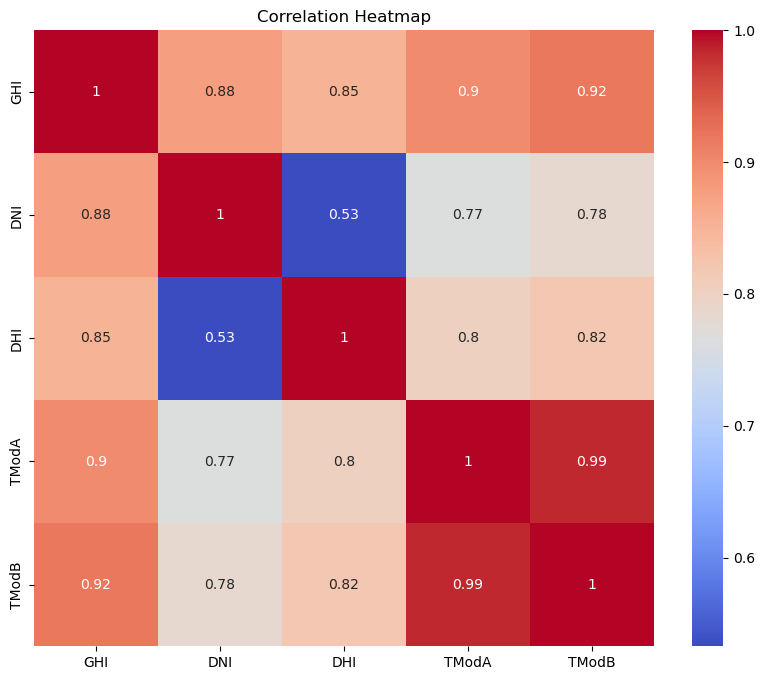

In [17]:
# 5. Correlation & Relationship Analysis
corr_cols = ['GHI', 'DNI', 'DHI', 'TModA', 'TModB']
if all(col in df_T.columns for col in corr_cols):
    corr = df_T[corr_cols].corr()
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, annot=True, cmap='coolwarm')
    plt.title('Correlation Heatmap')
    plt.show()

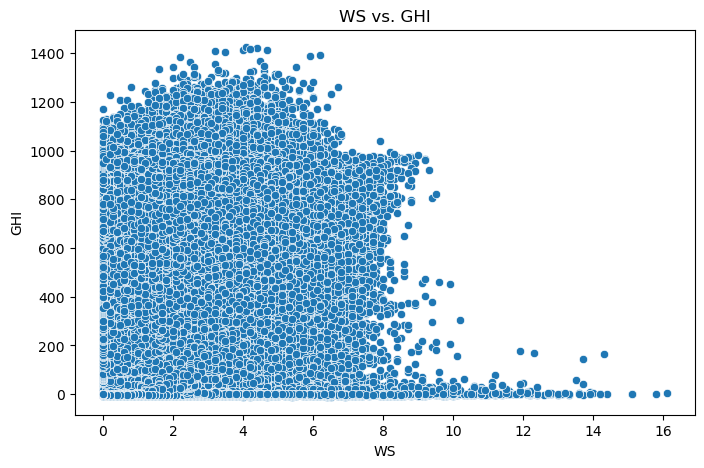

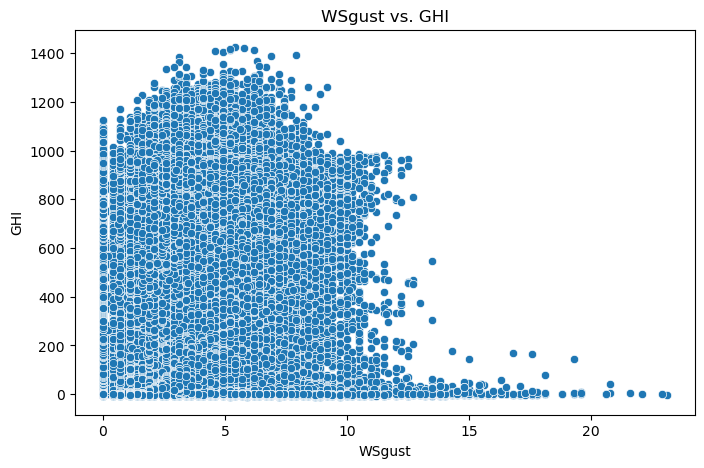

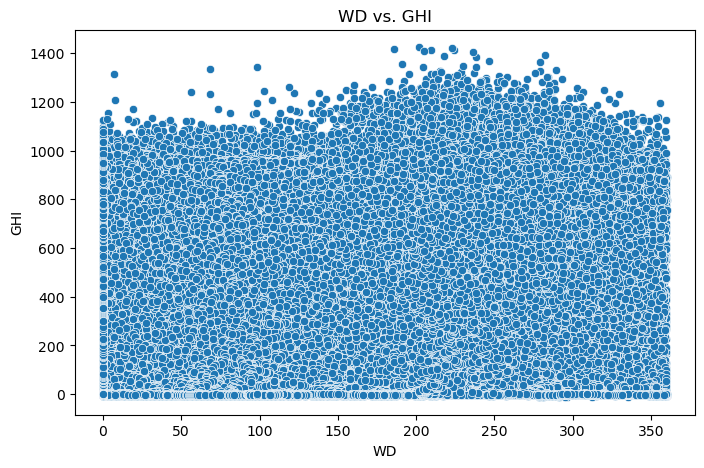

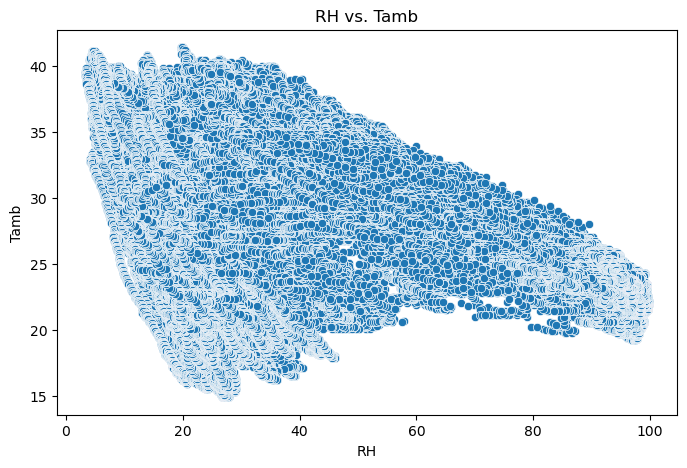

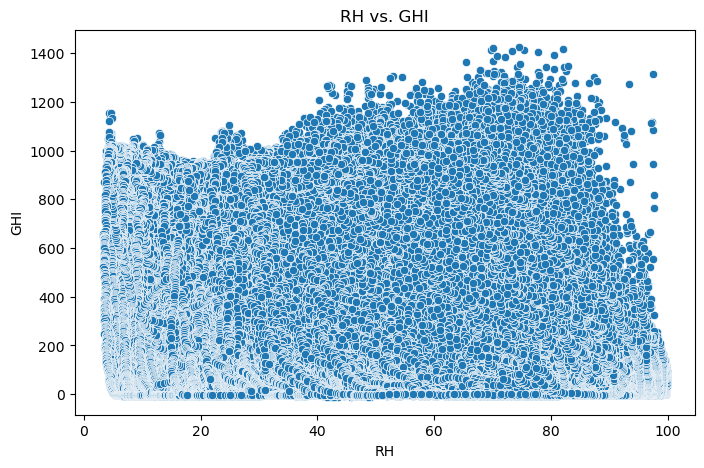

In [18]:
# Scatter plots
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_T, x='WS', y='GHI')
plt.title('WS vs. GHI')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_T, x='WSgust', y='GHI')
plt.title('WSgust vs. GHI')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_T, x='WD', y='GHI')
plt.title('WD vs. GHI')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_T, x='RH', y='Tamb')
plt.title('RH vs. Tamb')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_T, x='RH', y='GHI')
plt.title('RH vs. GHI')
plt.show()

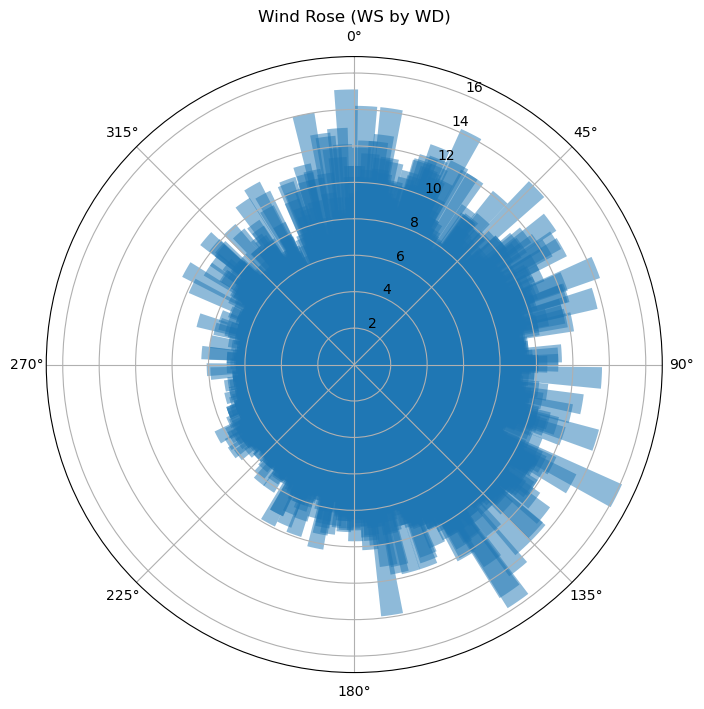

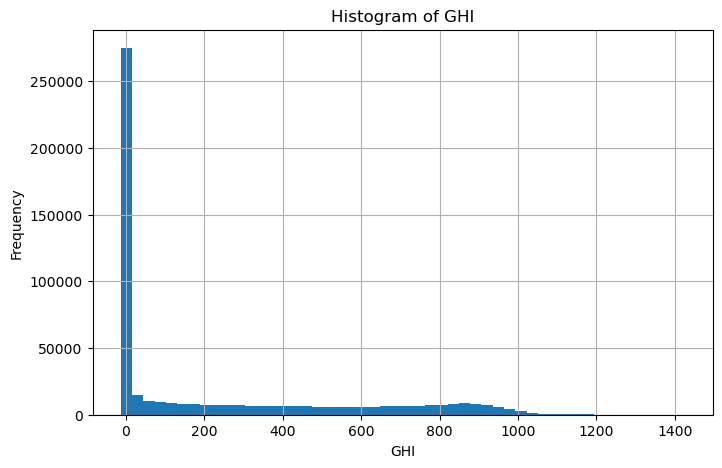

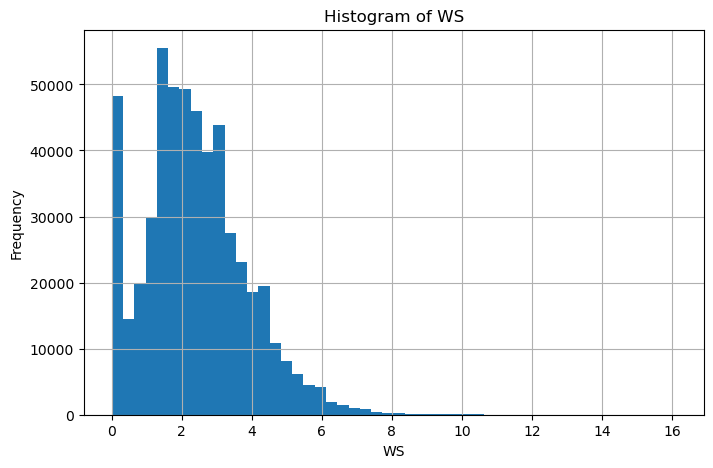

In [19]:
from math import radians
# 6. Wind & Distribution Analysis
# Simple wind rose (polar plot for WD and WS)
plt.figure(figsize=(8, 8))
ax = plt.subplot(111, projection='polar')
ax.bar([radians(w) for w in df_T['WD']], df_T['WS'], width=radians(5), alpha=0.5)
ax.set_theta_direction(-1)
ax.set_theta_zero_location('N')
plt.title('Wind Rose (WS by WD)')
plt.show()

# Histograms
plt.figure(figsize=(8, 5))
df_T['GHI'].hist(bins=50)
plt.title('Histogram of GHI')
plt.xlabel('GHI')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(8, 5))
df_T['WS'].hist(bins=50)
plt.title('Histogram of WS')
plt.xlabel('WS')
plt.ylabel('Frequency')
plt.show()


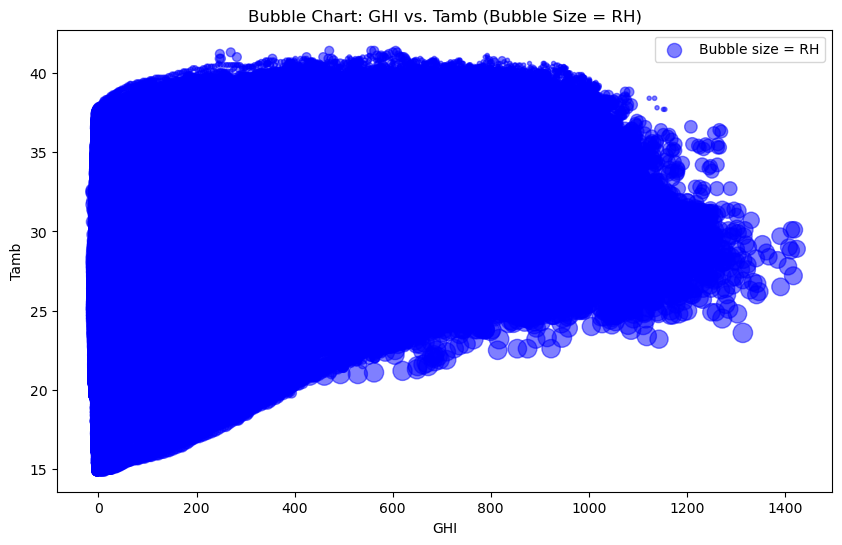

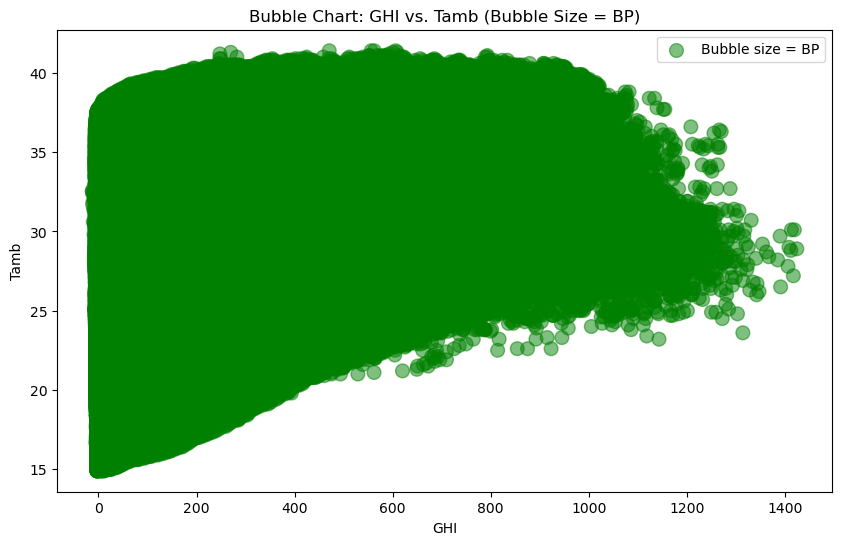

In [20]:
# 7. Temperature Analysis
#  Bubble Chart
plt.figure(figsize=(10, 6))
plt.scatter(df_T['GHI'], df_T['Tamb'], s=df_T['RH'] * 2, alpha=0.5, c='blue', label='Bubble size = RH')  # Scaled size
plt.title('Bubble Chart: GHI vs. Tamb (Bubble Size = RH)')
plt.xlabel('GHI')
plt.ylabel('Tamb')
plt.legend()
plt.show()

# Alternative with BP
plt.figure(figsize=(10, 6))
plt.scatter(df_T['GHI'], df_T['Tamb'], s=df_T['BP'] / 10, alpha=0.5, c='green', label='Bubble size = BP')  # Scaled size
plt.title('Bubble Chart: GHI vs. Tamb (Bubble Size = BP)')
plt.xlabel('GHI')
plt.ylabel('Tamb')
plt.legend()
plt.show()